# Regular experiments: layered vs. looped transformers

In [8]:
# Figure 2 depth/loop experiment (baseline and shared-weight looped transformer)

import torch
from matplotlib import pyplot as plt
import os
import numpy as np

from linear_transformer import generate_data, DataMode
from experiments_helper import (
    run_experiment_suite,
    compute_loss_dict,
    compute_dist_dict,
    plot_loss_curves,
    plot_parameter_matrices,
    plot_dist_to_identity,
)

np.set_printoptions(precision=2, suppress=True)
torch.set_printoptions(precision=2)

log_dir = 'log'
cur_dir = log_dir
os.makedirs(cur_dir, exist_ok=True)

In [9]:
# Problem parameters (defined in experiments_helper.py; edit them there so the
# helper functions see the same values)

from experiments_helper import (
    device, N, d, n_head, max_iters, hist_stride, stride, TEST_SEED,
)

print(f'Running on device: {device}.')

Running on device: cuda.


In [10]:
####################################
# Train layered and shared-weight looped transformers
####################################

filename_format = '/figure_two_layers_vs_loops_{}_{}.pth'
filename = cur_dir + filename_format.format(N, d)

In [ ]:
seeds = [0, 1, 2]
n_layers_loops = [1, 2, 5, 10]
model_types = ['layered', 'looped']

# This is replicating Figure 2 in Gatmiry et al. with an unconstrained top left corner of the matrix
hist_dict = run_experiment_suite(seeds, n_layers_loops, model_types, filename, freeze_p=False)  # [P-FIX] paper's P = [[0, 0], [0, 1]]

Run 1/24: seed=0, count=1, type=layered, N=20, mode=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear, freeze_p=False, learn_u=False
iter 0 | Loss: 5.274337291717529 | time: 0.008828878402709961 | gradnorm: 4.807002067565918
iter 1 | Loss: 5.061816692352295 | time: 0.006430864334106445 | gradnorm: 4.562503337860107
iter 2 | Loss: 4.949411869049072 | time: 0.006508350372314453 | gradnorm: 4.421471118927002
iter 3 | Loss: 4.871385097503662 | time: 0.0065364837646484375 | gradnorm: 4.326864242553711
iter 4 | Loss: 5.046316623687744 | time: 0.006479501724243164 | gradnorm: 4.587100028991699
iter 100 | Loss: 4.091986656188965 | time: 0.0040283203125 | gradnorm: 4.001680374145508
iter 200 | Loss: 3.2562427520751953 | time: 0.0033330917358398438 | gradnorm: 3.403515100479126
iter 300 | Loss: 2.613921642303467 | time: 0.0033299922943115234 | gradnorm: 2.83896803855896
iter 400 | Loss: 2.113097667694092 | time: 0.0033159255981445312 |

In [12]:
loss_dict = compute_loss_dict(hist_dict, test_seed=TEST_SEED)

(0, 1, 'layered', 20, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Testing model: seed=0, count=1, type=layered, N=20, train data=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear
(0, 1, 'looped', 20, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Testing model: seed=0, count=1, type=looped, N=20, train data=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear
(0, 2, 'layered', 20, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Testing model: seed=0, count=2, type=layered, N=20, train data=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear
(0, 2, 'looped', 20, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Testing model: seed=0, count=2, type=loop

In [13]:
####################################
# integrated test-loss comparison: layered vs shared-weight looped
####################################

fig_dir = 'figures'
os.makedirs(fig_dir, exist_ok=True)
iterations = np.arange(0, max_iters, stride)

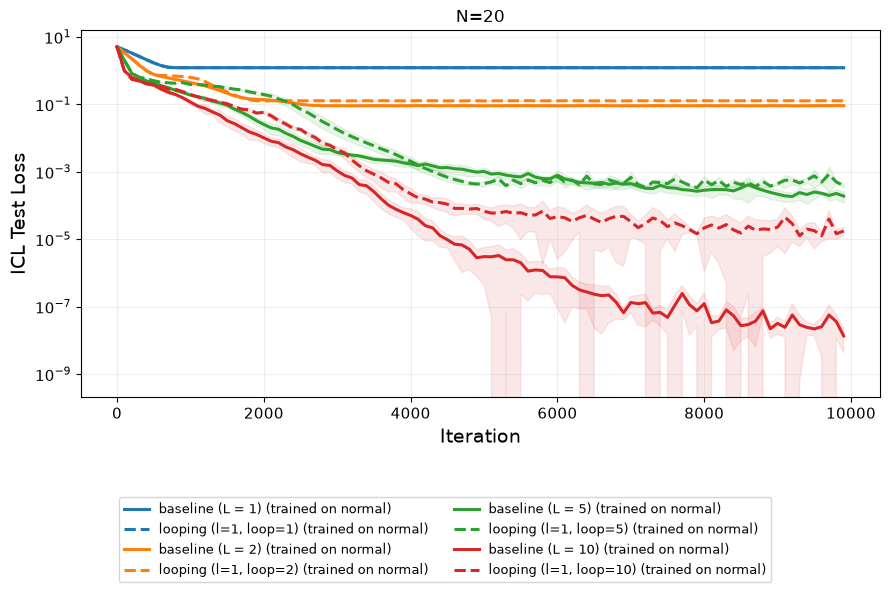

In [14]:
plot_loss_curves(loss_dict, n_layers_loops, ['layered', 'looped'], iterations, fig_dir=fig_dir)

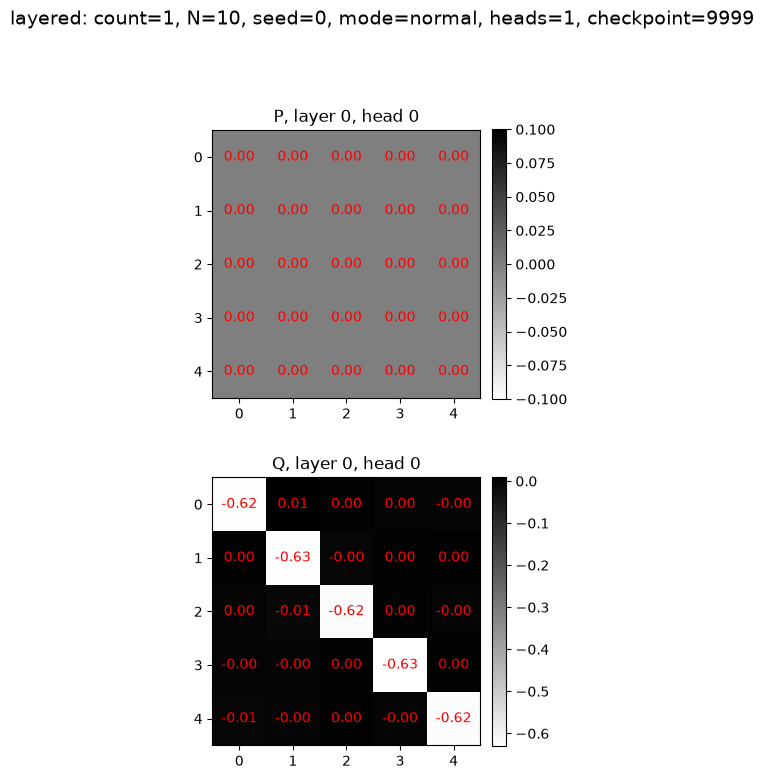

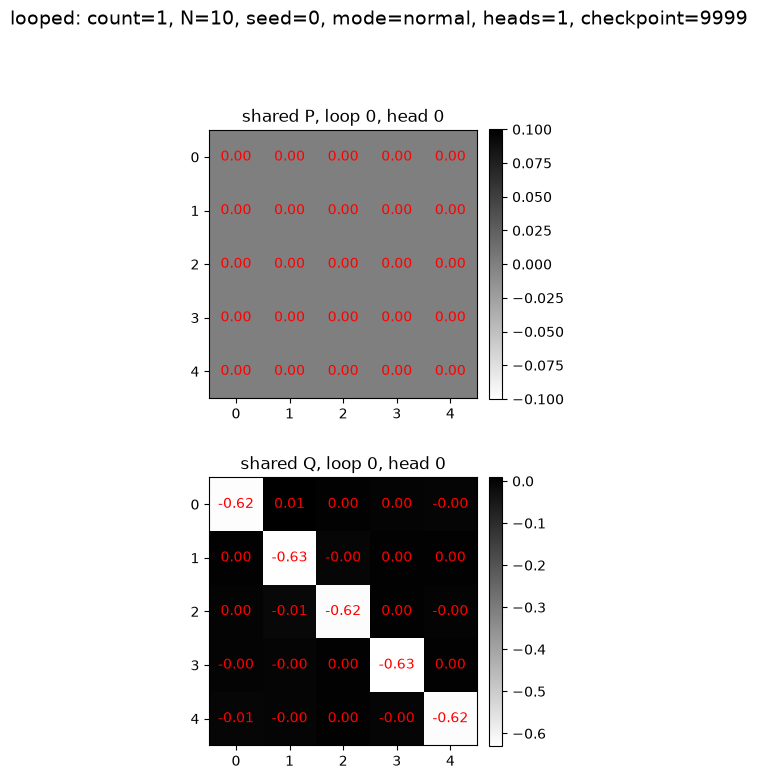

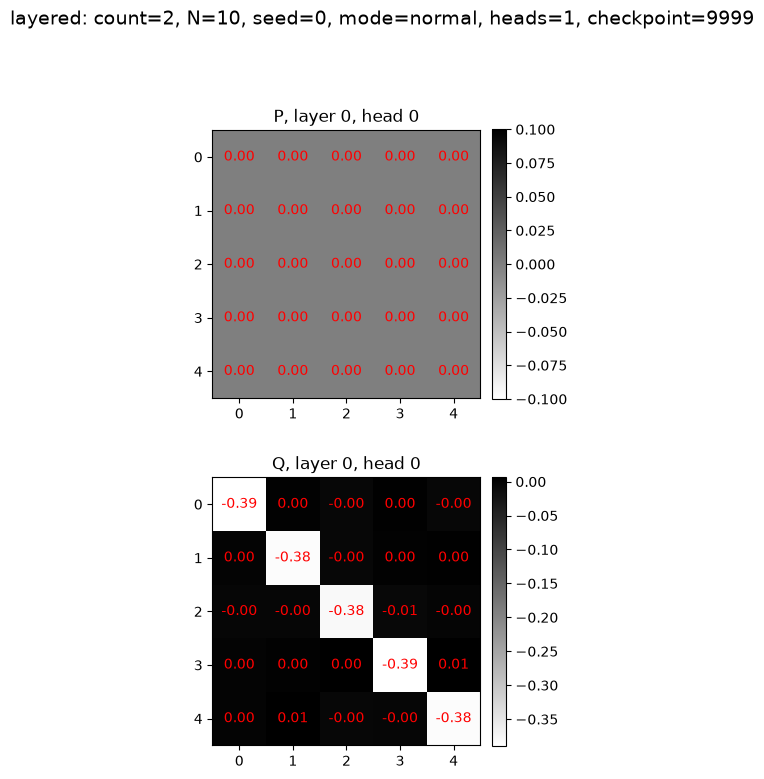

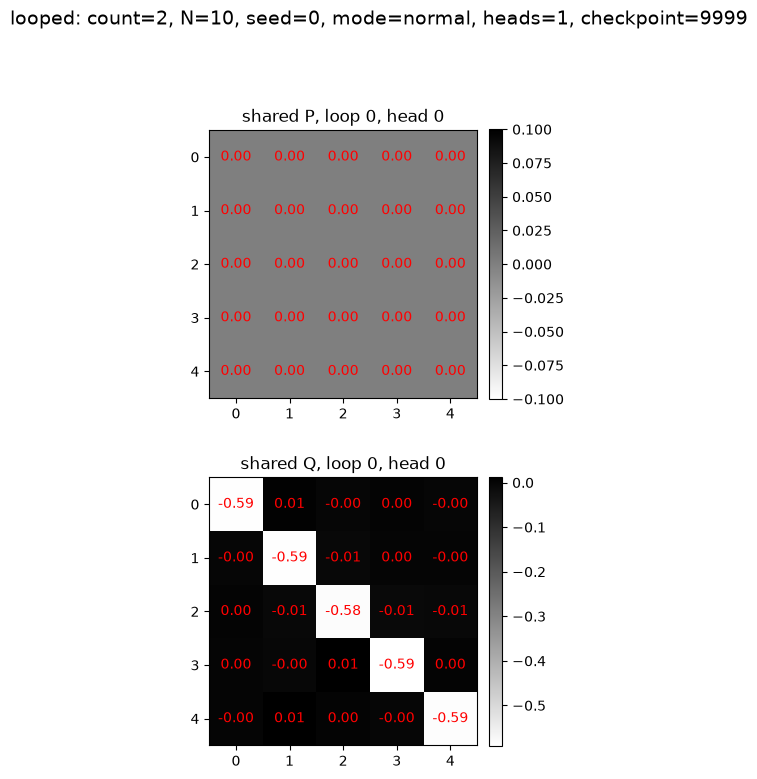

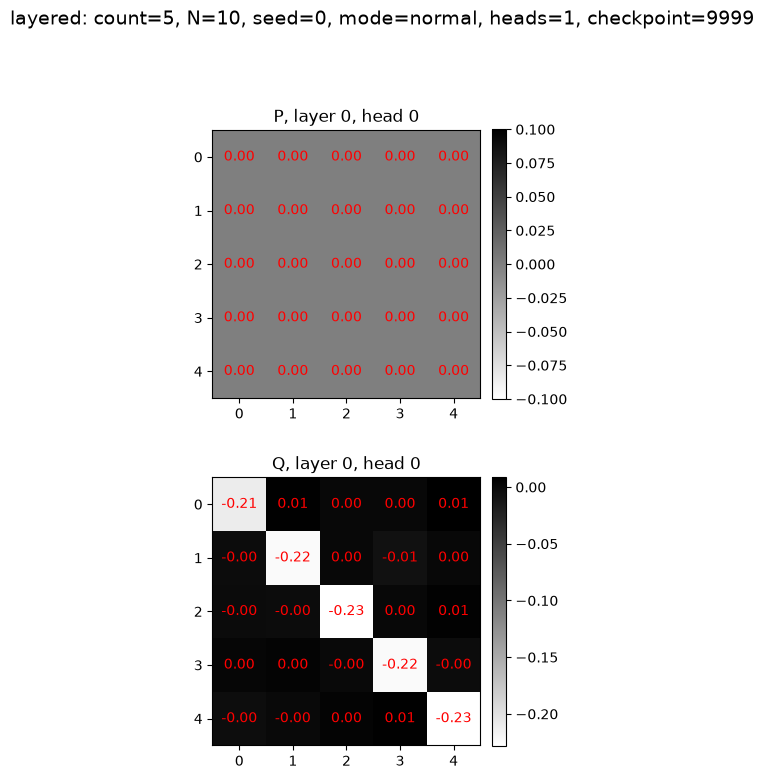

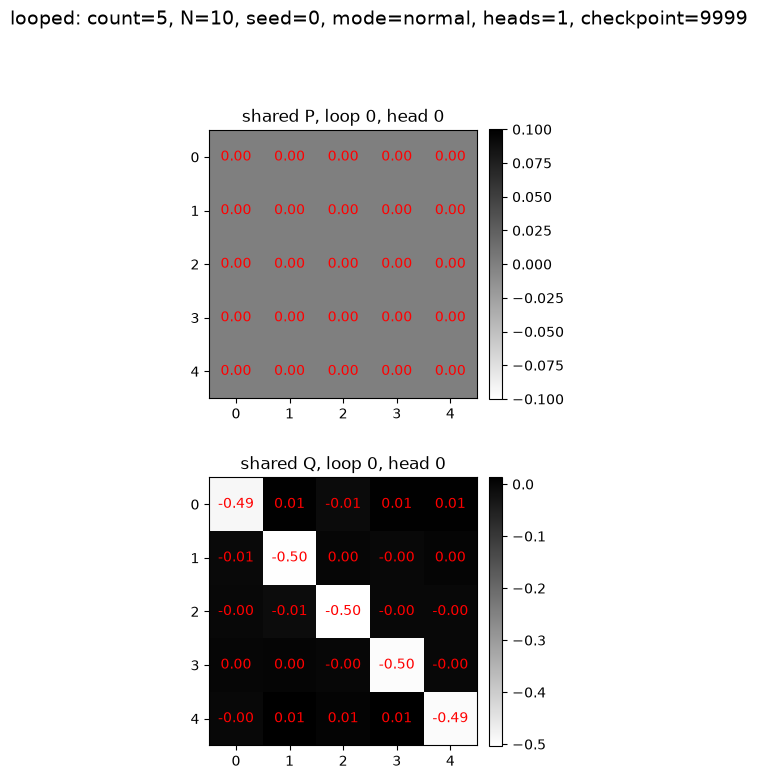

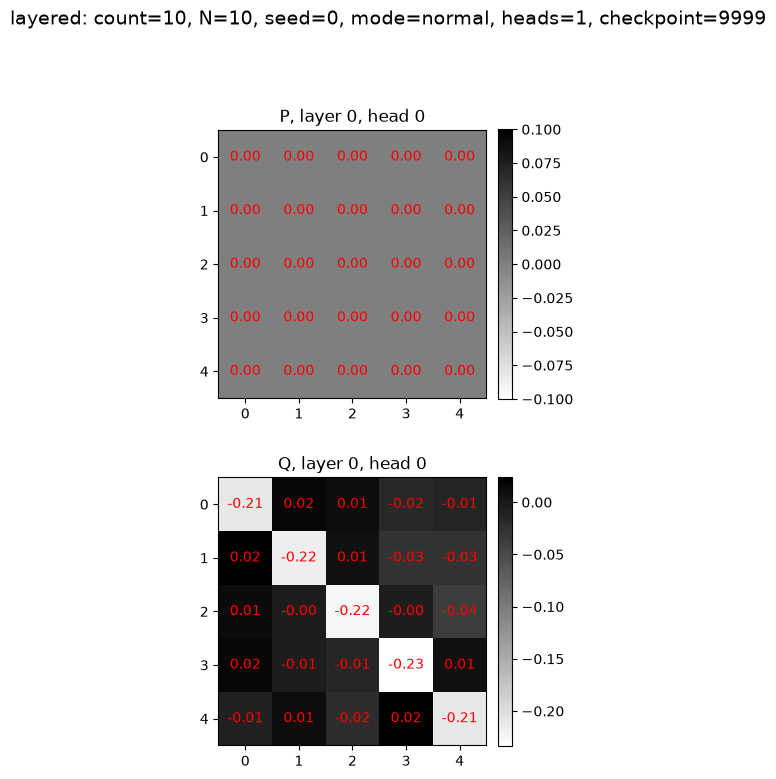

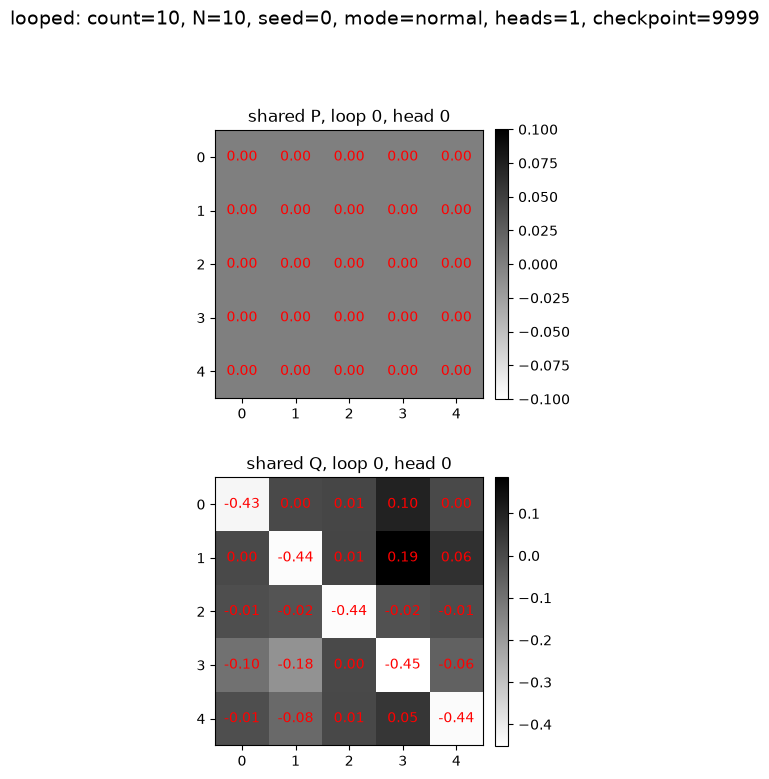

In [14]:
plot_parameter_matrices(hist_dict, seeds[0], n_layers_loops, model_types, n_head,
                        hist_stride=hist_stride, fig_dir=fig_dir)

In [15]:
iterations = np.arange(0, max_iters, stride)
dist_dict = compute_dist_dict(hist_dict, iterations, n_head, hist_stride=hist_stride)

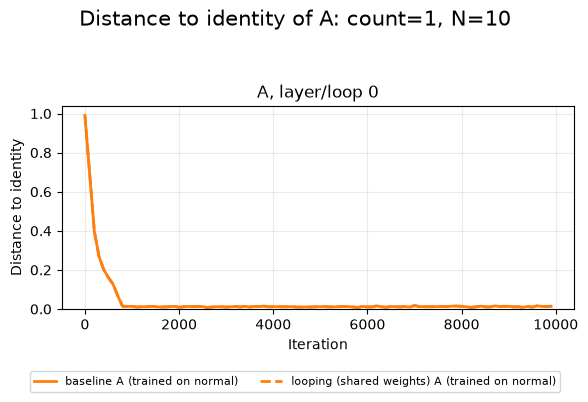

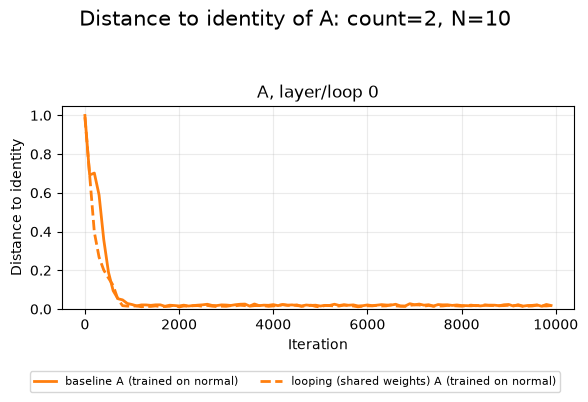

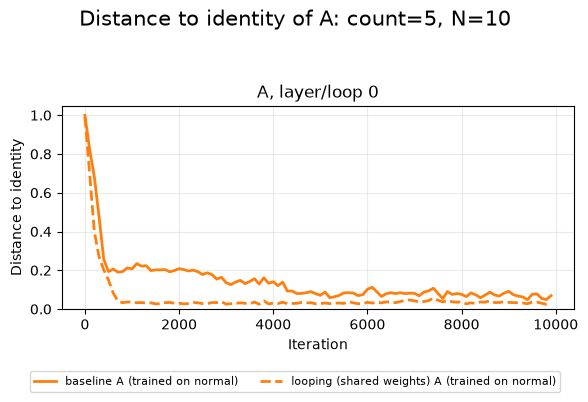

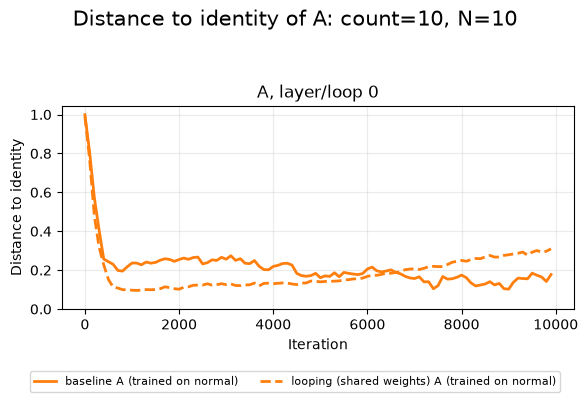

In [16]:
plot_dist_to_identity(dist_dict, n_layers_loops, iterations, fig_dir=fig_dir)